# PMXT continuous initialization diagnostic

This notebook compares the same negRisk basket and XRP ladder pair over the same six source hours, using a fixed one-hour warm-up versus earlier complete starting books plus every intervening archived update. The universe and v3 reconstruction policy are fixed. The pair is a diagnostic subset of its parent event; it does not certify every ladder relationship.

The default execution verifies saved local artifacts and fits no models. No network requests or new final-test access occur. See [the continuous initialization report](../docs/reports/pmxt_continuous_initialization.md).

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT/'src').exists(): ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
from src.common import sha256
from src.data.pmxt_archive import verify_dome
from src.data.pmxt_pilot import load_plan
DATA=ROOT/'data/pmxt/continuous_seed_v1'
RESULTS=ROOT/'results/pmxt_pilot/continuous_seed_v1'
design=json.loads((DATA/'study_design.json').read_text())
summary=json.loads((RESULTS/'summary.json').read_text())
for section in ['evidence_sha256','implementation_sha256']:
    for name,digest in summary[section].items():
        assert sha256(ROOT/name.replace(chr(92),'/'))==digest,name
for name,digest in summary['results_sha256'].items():
    assert sha256(RESULTS/name)==digest,name
for name in ['seed_v1_isolated','seed_v1_continuous']:
    folder,plan=load_plan(DATA/name)
    run=ROOT/'results/pmxt_pilot'/name/'source_validation_v3'
    replay=json.loads((run/'summary.json').read_text())
    assert sha256(folder/'source_validation_v3/design.json')==replay['design_sha256']
    frozen=json.loads((folder/'source_validation_v3/design.json').read_text())
    assert sha256(folder/'plan.json')==frozen['universe_sha256']
    for item in replay['inputs']:
        assert sha256(folder/item['path'].replace(chr(92),'/'))==item['sha256']
    for filename,digest in replay['derived_sha256'].items():
        assert sha256(folder/'source_validation_v3'/filename)==digest,filename
    for filename,digest in replay['results_sha256'].items():
        assert sha256(run/filename)==digest,filename
    for filename,digest in replay['implementation_sha256'].items():
        assert sha256(ROOT/filename.replace(chr(92),'/'))==digest,filename
    audit_dir=run.parent/'unknown_audit_v1'
    audit=json.loads((audit_dir/'summary.json').read_text())
    assert audit['replay_summary_sha256']==sha256(run/'summary.json')
    for filename,digest in audit['results_sha256'].items():
        assert sha256(audit_dir/filename)==digest,filename
assert not summary['models_trained'] and not summary['new_final_test_accessed']
assert not summary['net_pnl_estimated']
display(verify_dome(json.loads((ROOT/'data/pmxt/pilot_v1/dome_before.json').read_text())))
display(pd.read_parquet(DATA/'events.parquet')[['event_slug','diagnostic_scope']])
display(json.loads((DATA/'seed_search.json').read_text()))

{'unchanged': True, 'files': 2913}

,event_slug,diagnostic_scope
0,bitcoin-vs-gold-vs-sp-500-in-2026,complete_basket
1,what-price-will-xrp-hit-in-may-2026,single_pair_only


{'capture_start': '2026-05-04 23:00:00+00:00',
 'receipt_end': '2026-05-06 17:00:00+00:00',
 'seeded_tokens': 5,
 'required_tokens': 5,
 'sufficient': True,
 'latest_pre_scan_snapshots': {'108251591904413063139495882252154135107497878738832930637657538583440424739851': '2026-05-06 00:03:58.503000+00:00',
  '110278798232273153409473285242656277846127034405056021257247586947529803753453': '2026-05-05 23:47:46.547000+00:00',
  '4655209727295513535859117642120184432334179761721646415109648555849060899062': '2026-05-05 23:50:59.723000+00:00',
  '93207994086385268568874006716717433393966352959932150015626953142806317186909': '2026-05-05 00:52:43.261000+00:00',
  '32825140231045567473519733823753658145488577746690815504132235066565756510499': '2026-05-05 23:57:27.405000+00:00'},
 'charged_range_bytes': 909065300,
 'raw_cache_bytes': 1565662,
 'contiguous_receipt_hours': 42}

## Initialization and subsequent reliability

A starting snapshot establishes the complete recorded depth at one source time. Replaying all subsequent updates preserves that state across hour boundaries. Having a starting snapshot does not establish that every later update was captured or that source timestamps completely describe message ordering.

The first-scan token table is causal and excludes records at the scan timestamp. Label exclusions can additionally use later contradiction evidence. The paired hourly labels retain that distinction.

In [2]:
overview=pd.read_csv(RESULTS/'overview.csv')
tokens=pd.read_csv(RESULTS/'token_start.csv',dtype={'asset_id':str})
hours=pd.read_csv(RESULTS/'event_hours.csv',dtype={'event_id':str})
display(overview)
display(tokens)
display(pd.read_csv(RESULTS/'paired_labels.csv'))
assert len(hours)==2*summary['paired_event_hours']
assert (hours.loc[hours.label_occurrence.eq(0),'ruled_out_seconds']>=3600-1e-8).all()
assert (hours.loc[hours.label_occurrence.eq(1),'peak_value_lower_usd']>0).all()
exact=hours.label_peak_value_usd.notna()
assert np.allclose(hours.loc[exact,'peak_value_lower_usd'],hours.loc[exact,'peak_value_upper_usd'])
display(pd.read_csv(RESULTS/'unknown_reasons.csv'))

,scenario,capture_start,prefix_hours,receipt_hours,initialized_tokens_at_first_scan,causal_ask_available_tokens_at_first_scan,event_hours,positive_hours,negative_hours,unknown_hours,full_ask_time_fraction,full_book_time_fraction,determined_time_fraction,exact_value_hours,max_supported_gross_usd,analysis_contradiction_side_groups,missing_seed_unknown_seconds
0,isolated,2026-05-06 08:00:00+00:00,1.0,9,0,0,12,0,0,12,0.0,0.0,0.0,0,0.0,108,34617.331
1,continuous,2026-05-04 23:00:00+00:00,34.0,42,5,2,12,0,0,12,0.0,0.0,0.0,0,0.0,8076,0.000


,asset_id,initialized,latest_snapshot_source_ms,causal_ask_available,causal_ask_exact,causal_bid_available,ask_fault_reason,bid_fault_reason,analysis_best_price_contradiction_side_groups,first_issue_after_seed_ms,scenario
0,1082515919044130631394958822521541351074978787...,False,NaN,False,False,False,NaN,NaN,108,1.778071e+12,isolated
1,1102787982322731534094732852426562778461270344...,False,NaN,False,False,False,NaN,NaN,0,NaN,isolated
2,3282514023104556747351973382375365814548857774...,False,NaN,False,False,False,NaN,NaN,0,NaN,isolated
3,4655209727295513535859117642120184432334179761...,False,NaN,False,False,False,NaN,NaN,0,NaN,isolated
4,9320799408638526856887400671671743339396635295...,False,NaN,False,False,False,NaN,NaN,0,NaN,isolated
5,1082515919044130631394958822521541351074978787...,True,1.778026e+12,True,True,False,NaN,best_price_contradiction,256,1.777961e+12,continuous
6,1102787982322731534094732852426562778461270344...,True,1.778025e+12,False,False,False,best_price_contradiction,best_price_contradiction,6794,1.777957e+12,continuous
7,3282514023104556747351973382375365814548857774...,True,1.778025e+12,False,False,False,best_price_contradiction,best_price_contradiction,225,1.777945e+12,continuous
8,4655209727295513535859117642120184432334179761...,True,1.778025e+12,True,True,False,NaN,best_price_contradiction,0,1.777968e+12,continuous
9,9320799408638526856887400671671743339396635295...,True,1.777942e+12,False,False,False,best_price_contradiction,best_price_contradiction,801,1.777948e+12,continuous


,event_id,hour,label_occurrence_isolated,label_peak_value_usd_isolated,label_occurrence_continuous,label_peak_value_usd_continuous
0,106981,2026-05-06 09:00:00+00:00,NaN,NaN,NaN,NaN
1,438068,2026-05-06 09:00:00+00:00,NaN,NaN,NaN,NaN
2,106981,2026-05-06 10:00:00+00:00,NaN,NaN,NaN,NaN
3,438068,2026-05-06 10:00:00+00:00,NaN,NaN,NaN,NaN
4,106981,2026-05-06 11:00:00+00:00,NaN,NaN,NaN,NaN
5,438068,2026-05-06 11:00:00+00:00,NaN,NaN,NaN,NaN
6,106981,2026-05-06 12:00:00+00:00,NaN,NaN,NaN,NaN
7,438068,2026-05-06 12:00:00+00:00,NaN,NaN,NaN,NaN
8,106981,2026-05-06 13:00:00+00:00,NaN,NaN,NaN,NaN
9,438068,2026-05-06 13:00:00+00:00,NaN,NaN,NaN,NaN


,scenario,reason,primary_unknown_seconds,overlapping_unknown_seconds
0,isolated,missing_initial_snapshot,34617.331,34617.331
1,isolated,retrospective_best_price_drift,8582.667,8906.115
2,isolated,best_price_contradiction,0.002,0.002
3,isolated,crossed_final_group,0.000,0.000
4,isolated,malformed_group,0.000,0.000
5,isolated,unresolved_quantity_alternatives,0.000,0.000
6,isolated,other_unbounded_basket,0.000,0.000
7,continuous,missing_initial_snapshot,0.000,0.000
8,continuous,retrospective_best_price_drift,40529.420,40529.420
9,continuous,best_price_contradiction,2670.580,15929.209


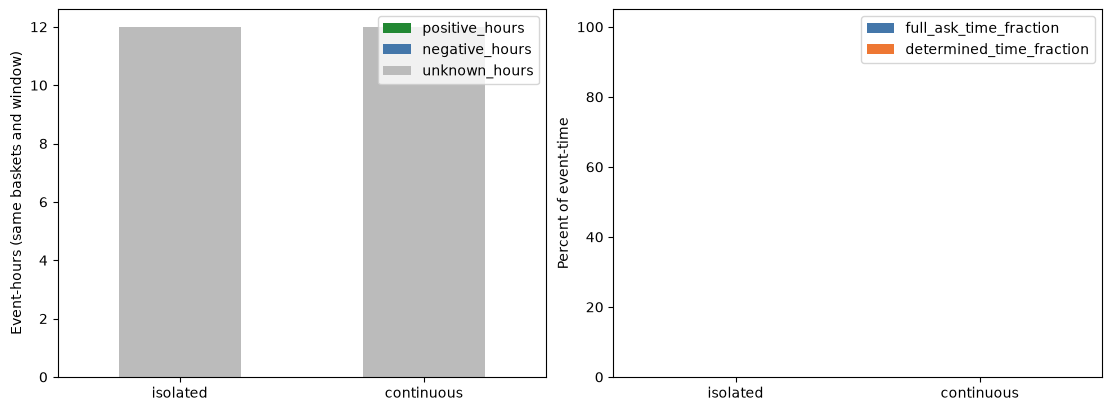

{'isolated': {'108251591904413063139495882252154135107497878738832930637657538583440424739851': [{'source_ms': 1778071487912,
    'side': 'SELL',
    'reconstructed_possible_best': [0.39],
    'reported_best': [0.42],
    'snapshot_anchor_ms': 1778070693883,
    'already_faulty': False},
   {'source_ms': 1778071488010,
    'side': 'SELL',
    'reconstructed_possible_best': [0.39],
    'reported_best': [0.42],
    'snapshot_anchor_ms': 1778070693883,
    'already_faulty': True},
   {'source_ms': 1778071488565,
    'side': 'SELL',
    'reconstructed_possible_best': [0.39],
    'reported_best': [0.42],
    'snapshot_anchor_ms': 1778070693883,
    'already_faulty': True},
   {'source_ms': 1778078494856,
    'side': 'BUY',
    'reconstructed_possible_best': [0.4],
    'reported_best': [0.39],
    'snapshot_anchor_ms': 1778075043901,
    'already_faulty': False},
   {'source_ms': 1778078525419,
    'side': 'BUY',
    'reconstructed_possible_best': [0.4],
    'reported_best': [0.39],
    'sna

{'asset_id': '108251591904413063139495882252154135107497878738832930637657538583440424739851',
 'anchor_source_time': '2026-05-06 12:31:33.883000+00:00',
 'decision_source_time': '2026-05-06 12:44:47.912000+00:00',
 'snapshot_best_ask': '0.39',
 'snapshot_best_ask_quantity': '16.68',
 'independently_reconstructed_best_ask': '0.39',
 'remaining_quantity': '16.68',
 'reported_best_asks': ['0.4200'],
 'intervening_ask_updates': 19,
 'updates_at_original_best': 0,
 'decision_rows': [{'timestamp': '2026-05-06 12:44:47.912000+00:00',
   'event_type': 'price_change',
   'side': 'BUY',
   'price': '0.3900',
   'size': '483.320000',
   'best_bid': '0.3900',
   'best_ask': '0.4200'}],
 'nearby_buy_trades': [{'source_time': '2026-05-06 12:44:47.931000+00:00',
   'delay_ms': 19.0,
   'price': '0.3900',
   'size': '16.680000'}],
 'note': 'Independent price-level-only trace. Trade handling, incomplete capture and timestamp semantics remain hypotheses; no depth repair or label change.'}

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
indexed=overview.set_index('scenario')
indexed[['positive_hours','negative_hours','unknown_hours']].plot.bar(stacked=True,ax=axes[0],rot=0,
    color=['#228833','#4477AA','#BBBBBB'])
axes[0].set_ylabel('Event-hours (same baskets and window)')
axes[0].set_xlabel('')
indexed[['full_ask_time_fraction','determined_time_fraction']].mul(100).plot.bar(ax=axes[1],rot=0,
    color=['#4477AA','#EE7733'])
axes[1].set_ylabel('Percent of event-time')
axes[1].set_ylim(0,105)
axes[1].set_xlabel('')
plt.show()
display(json.loads((RESULTS/'contradiction_examples.json').read_text()))
display(json.loads((RESULTS/'independent_ask_check.json').read_text()))

## Interpretation

This deliberately selected five-token subset tests initialization and post-seed consistency. Its label prevalence and price behavior do not represent the full Polymarket universe. New observed contradictions can reflect checks that became possible only after initialization; side-group counts include repeated evidence and are not independent packet-loss counts.

The hypothetical source clock, compatible closing-snapshot convention and finite two-hour receipt tail are unchanged assumptions. Quote values use zero fees, minimum size five and an initial 0.0001 tick until an observed change. Historical parameters remain unverified. A supported quote is not a fill or realised profit. The future economic primary remains 100 ms total source-update-to-order-arrival latency, uncapped capital/shares and displayed-depth constraints.

The original Dome study, isolated PMXT pilot, trained models and final evaluation remain preserved. Initializing depth across a chronological model split is permitted when it uses past records only; model fitting and any transformations still obey their own chronological training boundaries.

The independent Decimal/dictionary check reproduces the stale $0.39 ask without calling the v3 book implementation. A BUY trade 19 ms after the contradictory best-price update exactly matches the old 16.68-share ask quantity. That is evidence for investigating trade-related transitions, not proof of capture loss or justification for automatically subtracting every trade. The frozen v3 replay and its labels remain unchanged.